In [1]:
# Data Handling
import numpy as np
import pandas as pd

# Data Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Machine Learning
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

# Model Evaluation
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

print("All Libraries Imported Successfully!")

All Libraries Imported Successfully!


In [2]:
# Load Training Dataset
df = pd.read_csv('../data/train.csv')

# Display Dataset Information
print("Dataset Loaded Successfully!")
print("Dataset Shape:", df.shape)

# Display First 5 Rows
display(df.head())

Dataset Loaded Successfully!
Dataset Shape: (891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [3]:
# Separate Features and Target

X = df.drop(columns=['Survived'])
y = df['Survived']

# Display Shapes
print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

# Display First 5 Rows
display(X.head())
display(y.head())

Features Shape: (891, 11)
Target Shape: (891,)


,PassengerId,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


0    0
1    1
2    1
3    1
4    0
Name: Survived, dtype: int64

In [4]:
# Identify Numerical Columns
numerical_features = X.select_dtypes(include=['int64', 'float64']).columns.tolist()

# Identify Categorical Columns
categorical_features = X.select_dtypes(include=['object', 'str']).columns.tolist()

# Display Results
print("Numerical Features:")
print(numerical_features)

print("\nCategorical Features:")
print(categorical_features)

print("\nTotal Numerical Features:", len(numerical_features))
print("Total Categorical Features:", len(categorical_features))

Numerical Features:
['PassengerId', 'Pclass', 'Age', 'SibSp', 'Parch', 'Fare']

Categorical Features:
['Name', 'Sex', 'Ticket', 'Cabin', 'Embarked']

Total Numerical Features: 6
Total Categorical Features: 5


In [5]:
# Check Data Types
print("Column Data Types:")
print(X.dtypes)

# Check Missing Values
print("\nMissing Values:")
print(X.isnull().sum())

# Total Missing Values
print("\nTotal Missing Values:", X.isnull().sum().sum())

Column Data Types:
PassengerId      int64
Pclass           int64
Name               str
Sex                str
Age            float64
SibSp            int64
Parch            int64
Ticket             str
Fare           float64
Cabin              str
Embarked           str
dtype: object

Missing Values:
PassengerId      0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

Total Missing Values: 866


In [6]:
# Create Family Size
df['FamilySize'] = df['SibSp'] + df['Parch'] + 1

# Identify Passengers Traveling Alone
df['IsAlone'] = (df['FamilySize'] == 1).astype(int)

# Check Cabin Information
df['HasCabin'] = df['Cabin'].notna().astype(int)

# Extract Passenger Title from Name
df['Title'] = df['Name'].str.extract(r',\s*([^\.]+)\.')

# Display New Features
display(df[['FamilySize', 'IsAlone', 'HasCabin', 'Title']].head())

print("Feature Engineering Completed!")

,FamilySize,IsAlone,HasCabin,Title
0,2,0,0,Mr
1,2,0,1,Mrs
2,1,1,0,Miss
3,2,0,1,Mrs
4,1,1,0,Mr


Feature Engineering Completed!


In [7]:
# Separate Features and Target

X = df.drop(
    columns=['Survived', 'PassengerId', 'Name', 'Ticket', 'Cabin']
)

y = df['Survived']

# Display Selected Features
print("Selected Features:")
print(X.columns.tolist())

print("\nFeatures Shape:", X.shape)
print("Target Shape:", y.shape)

display(X.head())

Selected Features:
['Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked', 'FamilySize', 'IsAlone', 'HasCabin', 'Title']

Features Shape: (891, 11)
Target Shape: (891,)


,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked,FamilySize,IsAlone,HasCabin,Title
0,3,male,22.0,1,0,7.2500,S,2,0,0,Mr
1,1,female,38.0,1,0,71.2833,C,2,0,1,Mrs
2,3,female,26.0,0,0,7.9250,S,1,1,0,Miss
3,1,female,35.0,1,0,53.1000,S,2,0,1,Mrs
4,3,male,35.0,0,0,8.0500,S,1,1,0,Mr


In [8]:
# Split Dataset into Training and Testing

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Display Dataset Sizes

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)

Training Features: (712, 11)
Testing Features: (179, 11)
Training Target: (712,)
Testing Target: (179,)


In [9]:
# Identify Numerical and Categorical Columns

numerical_features = X_train.select_dtypes(
    include=['int64', 'float64']
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=['object', 'str']
).columns.tolist()

print("Numerical Features:")
print(numerical_features)

print("\nCategorical Features:")
print(categorical_features)

Numerical Features:
['Pclass', 'Age', 'SibSp', 'Parch', 'Fare', 'FamilySize', 'IsAlone', 'HasCabin']

Categorical Features:
['Sex', 'Embarked', 'Title']


In [11]:
# Numerical Data Preprocessing

numerical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

print("Numerical Preprocessing Pipeline Created!")

Numerical Preprocessing Pipeline Created!


In [12]:
# Categorical Data Preprocessing

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

print("Categorical Preprocessing Pipeline Created!")

Categorical Preprocessing Pipeline Created!


In [15]:
# Combine Numerical and Categorical Preprocessing

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numerical_transformer, numerical_features),
        ('cat', categorical_transformer, categorical_features)
    ]
)

print("Preprocessing Combined Successfully!")

Preprocessing Combined Successfully!


In [16]:
# Create Logistic Regression Pipeline

logistic_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(max_iter=1000))
])

# Train the Model
logistic_model.fit(X_train, y_train)

print("Logistic Regression Model Trained Successfully!")

Logistic Regression Model Trained Successfully!


In [17]:
# Make Predictions

y_pred_logistic = logistic_model.predict(X_test)

# Display First 10 Predictions

print("Actual Values:")
print(y_test.head(10).values)

print("\nPredicted Values:")
print(y_pred_logistic[:10])

Actual Values:
[0 0 1 0 1 1 1 0 0 0]

Predicted Values:
[0 0 0 0 1 1 1 1 0 0]


In [18]:
# Calculate Model Accuracy

logistic_accuracy = accuracy_score(y_test, y_pred_logistic)

# Display Accuracy

print("Logistic Regression Accuracy:",
      round(logistic_accuracy * 100, 2), "%")

Logistic Regression Accuracy: 83.24 %


In [19]:
# Generate Classification Report

logistic_report = classification_report(
    y_test,
    y_pred_logistic,
    target_names=['Not Survived', 'Survived']
)

print("Logistic Regression Classification Report:")
print(logistic_report)

Logistic Regression Classification Report:
              precision    recall  f1-score   support

Not Survived       0.85      0.88      0.87       110
    Survived       0.80      0.75      0.78        69

    accuracy                           0.83       179
   macro avg       0.83      0.82      0.82       179
weighted avg       0.83      0.83      0.83       179



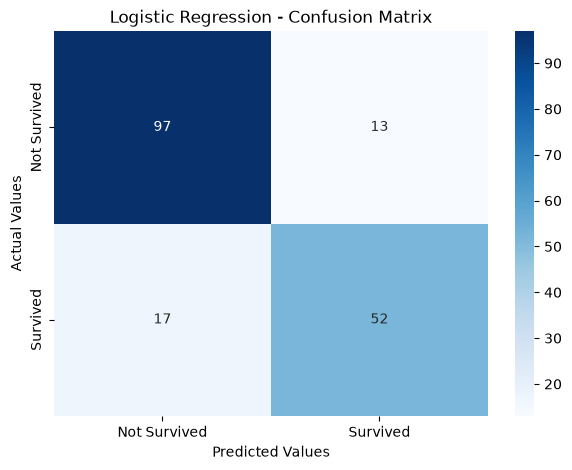

In [20]:
# Create Confusion Matrix

logistic_cm = confusion_matrix(y_test, y_pred_logistic)

# Visualize Confusion Matrix

plt.figure(figsize=(7, 5))

sns.heatmap(
    logistic_cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Not Survived', 'Survived'],
    yticklabels=['Not Survived', 'Survived']
)

plt.title('Logistic Regression - Confusion Matrix')
plt.xlabel('Predicted Values')
plt.ylabel('Actual Values')
plt.show()

In [21]:
# Create Decision Tree Pipeline

decision_tree_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', DecisionTreeClassifier(
        max_depth=5,
        random_state=42
    ))
])

# Train the Model
decision_tree_model.fit(X_train, y_train)

print("Decision Tree Model Trained Successfully!")

Decision Tree Model Trained Successfully!


In [22]:
# Make Predictions
y_pred_tree = decision_tree_model.predict(X_test)

# Display Actual and Predicted Values
print("Actual Values:")
print(y_test.head(10).values)

print("\nDecision Tree Predicted Values:")
print(y_pred_tree[:10])

Actual Values:
[0 0 1 0 1 1 1 0 0 0]

Decision Tree Predicted Values:
[0 0 0 0 0 0 1 1 0 0]


In [23]:
# Calculate Accuracy
tree_accuracy = accuracy_score(y_test, y_pred_tree)

# Display Accuracy
print("Decision Tree Accuracy:",
      round(tree_accuracy * 100, 2), "%")

Decision Tree Accuracy: 78.21 %


In [24]:
# Create Random Forest Pipeline

random_forest_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(
        n_estimators=200,
        max_depth=6,
        random_state=42
    ))
])

# Train the Model
random_forest_model.fit(X_train, y_train)

print("Random Forest Model Trained Successfully!")

Random Forest Model Trained Successfully!


In [25]:
# Make Predictions
y_pred_forest = random_forest_model.predict(X_test)

# Display Actual and Predicted Values
print("Actual Values:")
print(y_test.head(10).values)

print("\nRandom Forest Predicted Values:")
print(y_pred_forest[:10])

Actual Values:
[0 0 1 0 1 1 1 0 0 0]

Random Forest Predicted Values:
[0 0 0 0 1 1 1 1 0 0]


In [26]:
# Calculate Accuracy
forest_accuracy = accuracy_score(y_test, y_pred_forest)

# Display Accuracy
print("Random Forest Accuracy:",
      round(forest_accuracy * 100, 2), "%")

Random Forest Accuracy: 83.24 %


In [27]:
# Create Model Comparison Table

model_comparison = pd.DataFrame({
    'Model': [
        'Logistic Regression',
        'Decision Tree',
        'Random Forest'
    ],
    'Accuracy (%)': [
        round(logistic_accuracy * 100, 2),
        round(tree_accuracy * 100, 2),
        round(forest_accuracy * 100, 2)
    ]
})

# Sort Models by Accuracy
model_comparison = model_comparison.sort_values(
    by='Accuracy (%)',
    ascending=False
)

display(model_comparison)

,Model,Accuracy (%)
0,Logistic Regression,83.24
2,Random Forest,83.24
1,Decision Tree,78.21


In [28]:
# Select the Model with Highest Accuracy

best_model_name = model_comparison.iloc[0]['Model']

print("Best Model:", best_model_name)
print("Best Accuracy:",
      model_comparison.iloc[0]['Accuracy (%)'], "%")

# Select the Actual Model
best_model = {
    'Logistic Regression': logistic_model,
    'Decision Tree': decision_tree_model,
    'Random Forest': random_forest_model
}[best_model_name]

print("\nBest Model Selected Successfully!")

Best Model: Logistic Regression
Best Accuracy: 83.24 %

Best Model Selected Successfully!


In [29]:
# Load Test Dataset
test_df = pd.read_csv('../data/test.csv')

# Display Dataset Information
print("Test Dataset Loaded Successfully!")
print("Test Dataset Shape:", test_df.shape)

display(test_df.head())

Test Dataset Loaded Successfully!
Test Dataset Shape: (418, 11)


,PassengerId,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,892,3,"Kelly, Mr. James",male,34.5,0,0,330911,7.8292,NaN,Q
1,893,3,"Wilkes, Mrs. James (Ellen Needs)",female,47.0,1,0,363272,7.0000,NaN,S
2,894,2,"Myles, Mr. Thomas Francis",male,62.0,0,0,240276,9.6875,NaN,Q
3,895,3,"Wirz, Mr. Albert",male,27.0,0,0,315154,8.6625,NaN,S
4,896,3,"Hirvonen, Mrs. Alexander (Helga E Lindqvist)",female,22.0,1,1,3101298,12.2875,NaN,S


In [30]:
# Create New Features

test_df['FamilySize'] = test_df['SibSp'] + test_df['Parch'] + 1

test_df['IsAlone'] = (test_df['FamilySize'] == 1).astype(int)

test_df['HasCabin'] = test_df['Cabin'].notna().astype(int)

test_df['Title'] = test_df['Name'].str.extract(r',\s*([^\.]+)\.')

# Display New Features
display(test_df[
    ['FamilySize', 'IsAlone', 'HasCabin', 'Title']
].head())

print("Test Data Feature Engineering Completed!")

,FamilySize,IsAlone,HasCabin,Title
0,1,1,0,Mr
1,2,0,0,Mrs
2,1,1,0,Mr
3,1,1,0,Mr
4,3,0,0,Mrs


Test Data Feature Engineering Completed!


In [31]:
# Select Features for Prediction

X_kaggle_test = test_df.drop(
    columns=['PassengerId', 'Name', 'Ticket', 'Cabin']
)

# Check Selected Features
print("Test Features Shape:", X_kaggle_test.shape)

print("\nSelected Columns:")
print(X_kaggle_test.columns.tolist())

display(X_kaggle_test.head())

Test Features Shape: (418, 11)

Selected Columns:
['Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked', 'FamilySize', 'IsAlone', 'HasCabin', 'Title']


,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked,FamilySize,IsAlone,HasCabin,Title
0,3,male,34.5,0,0,7.8292,Q,1,1,0,Mr
1,3,female,47.0,1,0,7.0000,S,2,0,0,Mrs
2,2,male,62.0,0,0,9.6875,Q,1,1,0,Mr
3,3,male,27.0,0,0,8.6625,S,1,1,0,Mr
4,3,female,22.0,1,1,12.2875,S,3,0,0,Mrs


In [32]:
# Make Predictions on Kaggle Test Data

kaggle_predictions = best_model.predict(X_kaggle_test)

# Display First 10 Predictions

print("First 10 Predictions:")
print(kaggle_predictions[:10])

print("\nTotal Predictions:", len(kaggle_predictions))
print("Predictions Generated Successfully!")

First 10 Predictions:
[0 1 0 0 1 0 1 0 1 0]

Total Predictions: 418
Predictions Generated Successfully!


In [33]:
# Create Submission DataFrame

submission = pd.DataFrame({
    'PassengerId': test_df['PassengerId'],
    'Survived': kaggle_predictions
})

# Save Submission File
submission.to_csv(
    '../data/titanic_submission.csv',
    index=False
)

print("Kaggle Submission File Created Successfully!")

display(submission.head(10))

Kaggle Submission File Created Successfully!


,PassengerId,Survived
0,892,0
1,893,1
2,894,0
3,895,0
4,896,1
5,897,0
6,898,1
7,899,0
8,900,1
9,901,0


In [34]:
# Verify Submission File

print("Submission Shape:", submission.shape)

print("\nMissing Values:")
print(submission.isnull().sum())

print("\nDuplicate Passenger IDs:",
      submission['PassengerId'].duplicated().sum())

print("\nSurvival Value Counts:")
print(submission['Survived'].value_counts())

display(submission.head())

Submission Shape: (418, 2)

Missing Values:
PassengerId    0
Survived       0
dtype: int64

Duplicate Passenger IDs: 0

Survival Value Counts:
Survived
0    250
1    168
Name: count, dtype: int64


,PassengerId,Survived
0,892,0
1,893,1
2,894,0
3,895,0
4,896,1


In [35]:
# Check Submission Columns

print("Submission Columns:")
print(submission.columns.tolist())

# Check Valid Prediction Values
print("\nUnique Survival Values:")
print(submission['Survived'].unique())

# Check File Information
print("\nSubmission Information:")
submission.info()

print("\nFinal Submission File is Ready!")

Submission Columns:
['PassengerId', 'Survived']

Unique Survival Values:
[0 1]

Submission Information:
<class 'pandas.DataFrame'>
RangeIndex: 418 entries, 0 to 417
Data columns (total 2 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   PassengerId  418 non-null    int64
 1   Survived     418 non-null    int64
dtypes: int64(2)
memory usage: 6.7 KB

Final Submission File is Ready!
